# Examining Sub-Research Question 2

The second sub-research question is as follows: **'To what extent does the media type of the source material influence the content of the fan fictions on Archive of Our Own??'**

In [1]:
# Import package
import polars as pl
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df_metadata = pl.read_ndjson("./data/combined_metadata.jsonl") # Create the df_metadata DataFrame
df_metadata = df_metadata.unnest('metadata') # Turn the metadata column into 18 separate columns

fandoms = ["DC's Legends of Tomorrow (TV)", "Avatar: The Last Airbender (Cartoon 2005)", "Spider-Man: Spider-Verse (Sony Animated Movies)"]

# Select the target fandom and relationship categories
df_metadata = df_metadata.filter(
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]) |
    (pl.col("Fandom") == fandoms[2])) &
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M") |
    (pl.col("Category") == "F/M"))
)

df_metadata.head()

id,title,Additional Tags,Archive Warning,Category,Characters,Fandoms,Language,Rating,Relationship,author,chapters,completed,published,words,Fandom,Character,Collections,Series,Relationships
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""10012010""","""Just One Training""","""Explicit Sexual Content, Oral …","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Explicit""","""Sara Lance/Leonard Snart""","""by capnwho""","""1/1""","""""","""2017-02-28""","""1,470""","""DC's Legends of Tomorrow (TV)""",null,null,"""Just One Fixation""",null
"""10013705""","""Five Months More""","""Established Relationship, surp…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart""",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-02-28""","""505""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"
"""10018964""","""It Ends with a Kiss""","""Alpha/Beta/Omega Dynamics, Min…","""No Archive Warnings Apply""","""M/M""","""Leonard Snart, Ray Palmer, Mic…",null,"""English""","""Teen And Up Audiences""","""Ray Palmer/Leonard Snart""","""by Constantsnow""","""1/1""","""""","""2017-02-28""","""3,008""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10030784""","""Bet""",null,"""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""General Audiences""","""Sara Lance/Leonard Snart""","""by orphan_account""","""1/1""","""""","""2017-03-01""","""1,273""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10033958""","""For the Both of Us""","""Captain Canary, ficcingcaptain…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-03-01""","""1,067""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"


In [19]:
# Count the amount of fan works per fandom and category composition
# Filtered by F/F + M/M
ff_mm_tv_amt = df_metadata.filter(
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")) &
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]))
).select(pl.len())
ff_mm_film_amt = df_metadata.filter(
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")) &
    (pl.col("Fandom") == fandoms[2])
).select(pl.len())

# Filtered by F/M
fm_tv_amt = df_metadata.filter(
    (pl.col("Category") == "F/M") &
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]))
).select(pl.len())
fm_film_amt = df_metadata.filter(
    (pl.col("Category") == "F/M") &
    (pl.col("Fandom") == fandoms[2])
).select(pl.len())

print(f"""Homosexual Television Shows' Fan Works Amount: {ff_mm_tv_amt}
Homosexual Movies' Fan Works Amount: {ff_mm_film_amt}
Heterosexual Television Shows' Fan Works Amount: {fm_tv_amt}
Heterosexual Movies' Fan Works Amount: {fm_film_amt}""")

Homosexual Television Shows' Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 3809 │
└──────┘
Homosexual Movies' Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 1904 │
└──────┘
Heterosexual Television Shows' Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 2658 │
└──────┘
Heterosexual Movies' Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 1598 │
└──────┘


## 1. Ratings

### 1.1 Creating the Ratings Datasets

In [24]:
df_ratings_ff_mm_tv = df_metadata.filter(
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")) &
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]))
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Homosexual Television Show Freq"}).with_columns((pl.col("Homosexual Television Show Freq") / ff_mm_tv_amt.item(0,0) * 100).alias("Homosexual Television Show %")) # Filtered by F/F + M/M based on television shows
df_ratings_ff_mm_film = df_metadata.filter(
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")) &
    (pl.col("Fandom") == fandoms[2])
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Homosexual Movie Freq"}).with_columns((pl.col("Homosexual Movie Freq") / ff_mm_film_amt.item(0,0) * 100).alias("Homosexual Movie %")) # Filtered by F/F + M/M based on movies

df_ratings_fm_tv = df_metadata.filter(
    (pl.col("Category") == "F/M") &
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]))
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Heterosexual Television Show Freq"}).with_columns((pl.col("Heterosexual Television Show Freq") / fm_tv_amt.item(0,0) * 100).alias("Heterosexual Television Show %")) # Filtered by F/M based on television shows
df_ratings_fm_film = df_metadata.filter(
    (pl.col("Category") == "F/M") &
    (pl.col("Fandom") == fandoms[2])
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Heterosexual Movie Freq"}).with_columns((pl.col("Heterosexual Movie Freq") / fm_film_amt.item(0,0) * 100).alias("Heterosexual Movie %")) # Filtered by F/M based on movies

print("Homosexual Television Show Ratings Amount:")
df_ratings_ff_mm_tv.show(5)
print("Homosexual Movie Ratings Amount:")
df_ratings_ff_mm_film.show(5)
print("Heterosexual Television Show Ratings Amount:")
df_ratings_fm_tv.show(5)
print("Heterosexual Movie Ratings Amount:")
df_ratings_fm_film.show(5)

Homosexual Television Show Ratings Amount:


Rating,Homosexual Television Show Freq,Homosexual Television Show %
str,u32,f64
"""Teen And Up Audiences""",1352,35.494881
"""General Audiences""",1082,28.406406
"""Mature""",536,14.071935
"""Explicit""",484,12.706747
"""Not Rated""",355,9.320032


Homosexual Movie Ratings Amount:


Rating,Homosexual Movie Freq,Homosexual Movie %
str,u32,f64
"""Explicit""",691,36.292017
"""Teen And Up Audiences""",433,22.741597
"""Mature""",303,15.913866
"""General Audiences""",280,14.705882
"""Not Rated""",197,10.346639


Heterosexual Television Show Ratings Amount:


Rating,Heterosexual Television Show Freq,Heterosexual Television Show %
str,u32,f64
"""Teen And Up Audiences""",937,35.252069
"""General Audiences""",907,34.123401
"""Mature""",312,11.738149
"""Not Rated""",264,9.93228
"""Explicit""",238,8.954101


Heterosexual Movie Ratings Amount:


Rating,Heterosexual Movie Freq,Heterosexual Movie %
str,u32,f64
"""Explicit""",580,36.295369
"""Mature""",310,19.399249
"""General Audiences""",300,18.773467
"""Teen And Up Audiences""",282,17.647059
"""Not Rated""",126,7.884856


### 1.2 Visualizing the Ratings Datasets

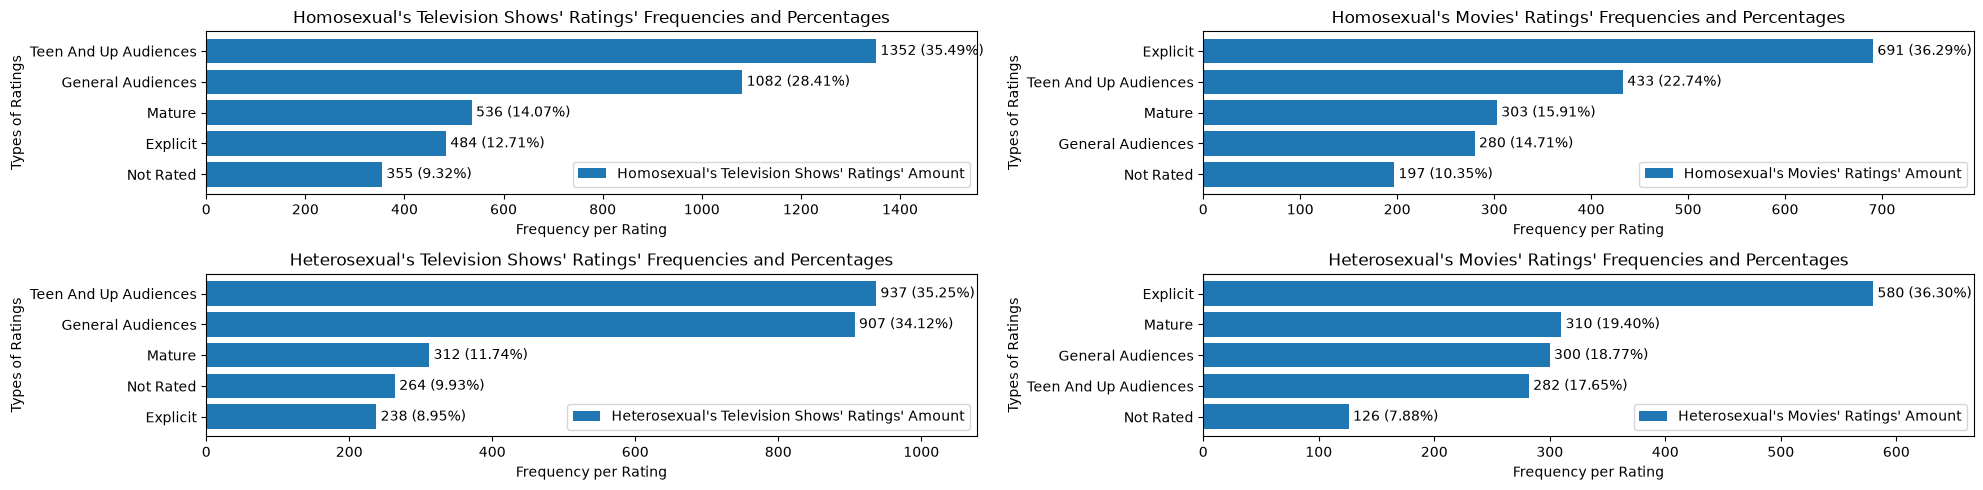

In [43]:
N = len(df_ratings_ff_mm_tv["Rating"]) # Amount of groups
width = 0.8 # Width of the bars
ind = np.arange(N) # Position of the bars on x-axis

fig, ax = plt.subplots(2, 2, figsize=(20, 5)) # Set figure size

# Filtered by F/F + M/M
# Plot a horizontal bar plot
p1 = ax[0, 0].barh(ind, df_ratings_ff_mm_tv["Homosexual Television Show Freq"], width, label="Homosexual's Television Shows' Ratings' Amount")
p2 = ax[0, 1].barh(ind, df_ratings_ff_mm_film["Homosexual Movie Freq"], width, label="Homosexual's Movies' Ratings' Amount")

# Combine the Frequencies and %
ff_mm_labels_tv = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_ratings_ff_mm_tv["Homosexual Television Show Freq"],
        df_ratings_ff_mm_tv["Homosexual Television Show %"]
    )
]
ff_mm_labels_film = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_ratings_ff_mm_film["Homosexual Movie Freq"],
        df_ratings_ff_mm_film["Homosexual Movie %"]
    )
]

#labels
ax[0, 0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0, 0].set_xlabel('Frequency per Rating')
ax[0, 0].set_title('Homosexual\'s Television Shows\' Ratings\' Frequencies and Percentages')
ax[0, 0].set_ylabel('Types of Ratings')
ax[0, 0].set_yticks(ind)
ax[0, 0].set_yticklabels(df_ratings_ff_mm_tv['Rating'])
ax[0, 0].legend(loc='best')

ax[0, 1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0, 1].set_xlabel('Frequency per Rating')
ax[0, 1].set_title('Homosexual\'s Movies\' Ratings\' Frequencies and Percentages')
ax[0, 1].set_ylabel('Types of Ratings')
ax[0, 1].set_yticks(ind)
ax[0, 1].set_yticklabels(df_ratings_ff_mm_film['Rating'])
ax[0, 1].legend(loc='best')

ax[0, 0].bar_label(p1, labels=ff_mm_labels_tv, padding=3)
ax[0, 1].bar_label(p2, labels=ff_mm_labels_film, padding=3)

# Add space for the labels
ax[0, 0].set_xlim(right=df_ratings_ff_mm_tv["Homosexual Television Show Freq"].max() * 1.15)
ax[0, 1].set_xlim(right=df_ratings_ff_mm_film["Homosexual Movie Freq"].max() * 1.15)

# Filtered by F/M
# Plot a horizontal bar plot
p1 = ax[1, 0].barh(ind, df_ratings_fm_tv["Heterosexual Television Show Freq"], width, label="Heterosexual's Television Shows' Ratings' Amount")
p2 = ax[1, 1].barh(ind, df_ratings_fm_film["Heterosexual Movie Freq"], width, label="Heterosexual's Movies' Ratings' Amount")

# Combine the Frequencies and %
fm_labels_tv = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_ratings_fm_tv["Heterosexual Television Show Freq"],
        df_ratings_fm_tv["Heterosexual Television Show %"]
    )
]
fm_labels_film = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_ratings_fm_film["Heterosexual Movie Freq"],
        df_ratings_fm_film["Heterosexual Movie %"]
    )
]

#labels
ax[1, 0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1, 0].set_xlabel('Frequency per Rating')
ax[1, 0].set_title('Heterosexual\'s Television Shows\' Ratings\' Frequencies and Percentages')
ax[1, 0].set_ylabel('Types of Ratings')
ax[1, 0].set_yticks(ind)
ax[1, 0].set_yticklabels(df_ratings_fm_tv['Rating'])
ax[1, 0].legend(loc='best')

ax[1, 1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1, 1].set_xlabel('Frequency per Rating')
ax[1, 1].set_title('Heterosexual\'s Movies\' Ratings\' Frequencies and Percentages')
ax[1, 1].set_ylabel('Types of Ratings')
ax[1, 1].set_yticks(ind)
ax[1, 1].set_yticklabels(df_ratings_fm_film['Rating'])
ax[1, 1].legend(loc='best')

ax[1, 0].bar_label(p1, labels=fm_labels_tv, padding=3)
ax[1, 1].bar_label(p2, labels=fm_labels_film, padding=3)

# Add space for the labels
ax[1, 0].set_xlim(right=df_ratings_fm_tv["Heterosexual Television Show Freq"].max() * 1.15)
ax[1, 1].set_xlim(right=df_ratings_fm_film["Heterosexual Movie Freq"].max() * 1.15)

plt.tight_layout()
plt.show()